# Procurement challenge: choose the analysis

A follow-on to the guided supplier review. **Choose the function, choose its settings, then explain the evidence.** The calculation methods are familiar; the data and purchasing decision are new.

Estimated working time: **40–50 minutes**, followed by discussion. Work individually or in pairs.


## Business brief

Your company must purchase **10,000 FILTER25 industrial filter cartridges for July**. Suppliers A, B and C offer the same specification in pieces and EUR. The review date is **30 June 2026**.

Management has received five claims about the suppliers. Investigate each claim before recommending a purchasing approach. Use the evidence in this dataset rather than the conclusions from the VALVE20 exercise.

Current acceptance criteria: **Approved** qualification, at least **85% promised-date on-time delivery**, and at most **1.0% defective inspected pieces**. Also assess the proposed **0.5% quality ceiling**. Supplier approval and available July capacity are stated assumptions shown in Setup. Adding capacities assumes these quantities can be supplied within July; it does not determine a daily receipt schedule.

The data are synthetic: **40 closed orders for A, 60 for B and 80 for C**, plus two open orders and one unconfirmed receipt per supplier. All three suppliers cover the same order-date window. Unequal sample sizes require percentages and clearly stated denominators; raw counts alone are insufficient.


## Data and setup

One row represents one purchase order for FILTER25. A closed order records one final receipt; any unreceived balance is cancelled. Every received piece in a closed order is inspected. Rework restores defective pieces, while the initial inspection failures remain recorded. Open and unconfirmed receipts have no final outcome and must not count as successful deliveries.

| Field group | Meaning and units |
|---|---|
| `PO_ID`, `Supplier`, `Product_Code` | Order, supplier and item identifiers |
| `PO_Date`, `Promised_Date`, `Actual_Receipt_Date`, `Status` | Order timing and whether the outcome is known |
| `Ordered_Qty`, `Received_Qty`, `Inspected_Qty`, `Defective_Qty` | Quantities in pieces |
| `Unit_Price_EUR` | Purchase price per received piece |
| `Freight_EUR`, `Inspection_Cost_EUR`, `Rework_Cost_EUR` | Separate EUR amounts per order |

The notebook contains the calculation functions. The setup cell loads the adjacent challenge CSV when available; otherwise it reads the same CSV from GitHub. The GitHub copy requires the challenge files to be pushed first. Run Setup once and review its first rows, status counts and capacity assumptions. You do not need to edit setup or implement new functions.


In [1]:
from pathlib import Path
import pandas as pd
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib', 'inline')

HELPER_SOURCE = '"""Functions for the FILTER25 supplier review challenge."""\nimport pandas as pd\nimport numpy as np\nimport matplotlib.pyplot as plt\nfrom IPython.display import display\nREVIEW_DATE = pd.Timestamp(\'2026-06-30\')\nJULY_REQUIREMENT = 10000\n\ndef prepare(orders):\n    d=orders.copy()\n    for col in [\'PO_Date\',\'Promised_Date\',\'Actual_Receipt_Date\']:\n        d[col]=pd.to_datetime(d[col],errors=\'raise\')\n    d[\'Lead_Days\']=(d.Actual_Receipt_Date-d.PO_Date).dt.days\n    d[\'Days_After_Promise\']=(d.Actual_Receipt_Date-d.Promised_Date).dt.days\n    return d\n\ndef completed(orders):\n    return orders.loc[orders.Status.eq(\'Closed\') & orders.Actual_Receipt_Date.notna()].copy()\n\ndef _supplier_metrics(orders):\n    rows=[]\n    for supplier,g in completed(orders).groupby(\'Supplier\'):\n        received=g.Received_Qty.sum();inspected=g.Inspected_Qty.sum()\n        purchase=(g.Received_Qty*g.Unit_Price_EUR).sum()\n        extra=g[[\'Freight_EUR\',\'Inspection_Cost_EUR\',\'Rework_Cost_EUR\']].sum().sum()\n        rows.append({\'Supplier\':supplier,\'Completed POs\':len(g),\'Mean days\':g.Lead_Days.mean(),\n          \'Std days\':g.Lead_Days.std(ddof=1),\'Promised-date OTD %\':g.Days_After_Promise.le(0).mean()*100,\n          \'In-full %\':g.Received_Qty.ge(g.Ordered_Qty).mean()*100,\n          \'Flagged POs\':int(g.Defective_Qty.gt(0).sum()),\'Flagged PO %\':g.Defective_Qty.gt(0).mean()*100,\n          \'Inspected units\':int(inspected),\'Defective units\':int(g.Defective_Qty.sum()),\n          \'Defective unit %\':g.Defective_Qty.sum()/inspected*100,\n          \'Purchase EUR/unit\':purchase/received,\'Recorded cost EUR/unit\':(purchase+extra)/received})\n    return pd.DataFrame(rows).set_index(\'Supplier\')\n\ndef baseline(orders, profiles):\n    """Show initial rows, order status counts and stated supplier assumptions."""\n    display(orders.head(3))\n    display(profiles)\n    display(orders.groupby([\'Supplier\', \'Status\']).size().unstack(fill_value=0))\n    print(\'Review: 30 June 2026. FILTER25, pieces, EUR. July requirement: 10,000 units.\')\n    print(\'Use closed orders with known final receipts for historical comparisons; keep unresolved records separate.\')\n\n\ndef show_delivery(orders, supplier=\'A\'):\n    """Return delivery statistics and plot one supplier using common histogram axes."""\n    g = completed(orders)\n    available = sorted(g.Supplier.unique())\n    if supplier not in available:\n        raise ValueError(f\'Choose a supplier from {available}.\')\n    m = _supplier_metrics(orders)\n    display(m[[\'Completed POs\', \'Mean days\', \'Std days\']].round(2))\n    bins = np.arange(g.Lead_Days.min() - .5, g.Lead_Days.max() + 1.5, 1)\n    highest = max(np.histogram(group.Lead_Days, bins=bins)[0].max() for _, group in g.groupby(\'Supplier\'))\n    selected = g.loc[g.Supplier.eq(supplier), \'Lead_Days\']\n    fig, ax = plt.subplots(figsize=(8, 3))\n    ax.hist(selected, bins=bins, color=\'#5B9BD5\', edgecolor=\'white\')\n    ax.set(xlabel=\'Calendar days from order to receipt\', ylabel=\'Completed orders\',\n           title=f\'Supplier {supplier}: {len(selected)} completed orders\',\n           xlim=(bins[0], bins[-1]), ylim=(0, highest * 1.15))\n    plt.tight_layout(); plt.show()\n    print(\'Use the mean for average speed and standard deviation for variation. Histograms share common axes; supplier sample sizes differ.\')\n    return m.loc[supplier]\n\ndef show_target(orders,target_days=10):\n    if target_days not in [10,12]:raise ValueError(\'Choose 10 or 12 days.\')\n    g=completed(orders);m=_supplier_metrics(orders)\n    count=g.groupby(\'Supplier\').Lead_Days.apply(lambda x:int(x.le(target_days).sum()))\n    result=pd.DataFrame({\'Completed POs\':m[\'Completed POs\'],\'Within internal target\':count,\'Within target %\':count/m[\'Completed POs\']*100,\'Promised-date OTD %\':m[\'Promised-date OTD %\']})\n    display(result.round(2));ax=result[[\'Within target %\',\'Promised-date OTD %\']].plot.bar(figsize=(8,3.6),ylim=(0,105),color=[\'#5B9BD5\',\'#ED7D31\']);plt.ylabel(\'Completed orders (%)\');ax.set_title(f\'Internal target: {target_days} calendar days\',pad=32);ax.legend(loc=\'lower center\',bbox_to_anchor=(.5,1.01),ncol=2,frameon=False);plt.xticks(rotation=0);plt.tight_layout();plt.show()\n    print(\'The internal target is a hypothetical reporting rule. Original promised dates and actual receipts stay unchanged.\')\n    return result\n\ndef show_quality(orders,view=\'orders\'):\n    if view not in [\'orders\',\'units\']:raise ValueError(\'Choose orders or units.\')\n    m=_supplier_metrics(orders);display(m[[\'Completed POs\',\'Flagged POs\',\'Flagged PO %\',\'Inspected units\',\'Defective units\',\'Defective unit %\']].round(2))\n    col=\'Flagged PO %\' if view==\'orders\' else \'Defective unit %\'\n    m[col].plot.bar(figsize=(7,3),color=\'#5B9BD5\',ylim=(0,max(1,float(m[col].max())*1.15)));plt.ylabel(col);plt.title(\'Orders with any defect\' if view==\'orders\' else \'Defective units among inspected units\');plt.xticks(rotation=0);plt.tight_layout();plt.show()\n    print(\'All received units in the closed orders were inspected. A flagged order may contain one or many defective units. Read the axis: the two charts use different scales.\')\n    return m\n\ndef show_cost(orders,basis=\'purchase\'):\n    if basis not in [\'purchase\',\'recorded\']:raise ValueError(\'Choose purchase or recorded.\')\n    m=_supplier_metrics(orders);display(m[[\'Purchase EUR/unit\',\'Recorded cost EUR/unit\']].round(3))\n    col=\'Purchase EUR/unit\' if basis==\'purchase\' else \'Recorded cost EUR/unit\'\n    m[col].plot.bar(figsize=(7,3),color=\'#5B9BD5\',ylim=(0,float(m[col].max())*1.15));plt.ylabel(\'EUR per received unit\');plt.title(\'Purchase price\' if basis==\'purchase\' else \'Recorded procurement cost\');plt.xticks(rotation=0);plt.tight_layout();plt.show()\n    print(\'Recorded cost = purchase + freight + inspection + rework, divided by received units. These case records exclude downtime, financing, administration and later lifecycle costs.\')\n    return m\n\ndef screen_suppliers(orders, profiles, max_defective_pct=1.0, required_units=JULY_REQUIREMENT):\n    """Check approval, 85% promised-date OTD, a chosen defect ceiling and capacity."""\n    if max_defective_pct not in [1.0, .5]:\n        raise ValueError(\'Choose 1.0 or 0.5 percent.\')\n    m = _supplier_metrics(orders).join(profiles.set_index(\'Supplier\'))\n    m[\'Approved\'] = m.Qualification.eq(\'Approved\')\n    m[\'Delivery passes\'] = m[\'Promised-date OTD %\'].ge(85)\n    m[\'Quality passes\'] = m[\'Defective unit %\'].le(max_defective_pct)\n    m[\'Eligible\'] = m[[\'Approved\', \'Delivery passes\', \'Quality passes\']].all(axis=1)\n    display(m[[\'Qualification\', \'Promised-date OTD %\', \'Defective unit %\',\n               \'Available_Capacity_July_units\', \'Delivery passes\', \'Quality passes\', \'Eligible\']].round(3))\n    capacity = int(m.loc[m.Eligible, \'Available_Capacity_July_units\'].sum())\n    print(f\'July requirement: {required_units:,} units. Eligible capacity: {capacity:,}. Capacity gap: {max(0, required_units-capacity):,}.\')\n    print(\'Capacity is assumed available for July. This screen does not optimise an order split or establish future supplier performance.\')\n    return m\n'
exec(compile(HELPER_SOURCE, 'procurement_challenge_helpers.py', 'exec'))

DATA_URL = 'https://raw.githubusercontent.com/saikisri97/17_Hof_Lecture_Code_Pingo/refs/heads/main/SCA_2026/Procurement_Supplier_Management/data/procurement_challenge_data.csv'
local_data = Path('data/procurement_challenge_data.csv')
data_source = local_data if local_data.exists() else DATA_URL
orders_raw = pd.read_csv(data_source)
required = {'PO_ID', 'Supplier', 'Product_Code', 'Product', 'Unit', 'Currency',
            'PO_Date', 'Promised_Date', 'Actual_Receipt_Date', 'Status',
            'Ordered_Qty', 'Received_Qty', 'Inspected_Qty', 'Defective_Qty',
            'Unit_Price_EUR', 'Freight_EUR', 'Inspection_Cost_EUR', 'Rework_Cost_EUR'}
if not required.issubset(orders_raw.columns):
    raise ValueError(f'The challenge CSV is missing fields: {sorted(required-set(orders_raw.columns))}')
orders = prepare(orders_raw)
# Hypothetical approval and available July capacity; these are case assumptions.
suppliers = pd.DataFrame([
    ['A', 'Approved', 5000], ['B', 'Approved', 4000], ['C', 'Approved', 7000],
], columns=['Supplier', 'Qualification', 'Available_Capacity_July_units'])
print(f'Loaded {len(orders_raw)} purchase-order records for FILTER25.')
baseline(orders, suppliers)


Loaded 189 purchase-order records for FILTER25.


,PO_ID,Supplier,Product_Code,Product,Unit,Currency,PO_Date,Promised_Date,Actual_Receipt_Date,Status,Ordered_Qty,Received_Qty,Inspected_Qty,Defective_Qty,Unit_Price_EUR,Freight_EUR,Inspection_Cost_EUR,Rework_Cost_EUR,Lead_Days,Days_After_Promise
0,CH-A-001,A,FILTER25,25 mm industrial filter cartridge,piece,EUR,2026-01-02,2026-01-13,2026-01-06,Closed,300,280.0,280.0,24.0,8.5,616.0,112.0,192.0,4.0,-7.0
1,CH-A-002,A,FILTER25,25 mm industrial filter cartridge,piece,EUR,2026-01-06,2026-01-17,2026-01-11,Closed,600,580.0,580.0,24.0,8.5,1276.0,232.0,192.0,5.0,-6.0
2,CH-A-003,A,FILTER25,25 mm industrial filter cartridge,piece,EUR,2026-01-09,2026-01-20,2026-01-15,Closed,900,880.0,880.0,24.0,8.5,1936.0,352.0,192.0,6.0,-5.0


,Supplier,Qualification,Available_Capacity_July_units
0,A,Approved,5000
1,B,Approved,4000
2,C,Approved,7000


Status,Closed,Open,Receipt_unconfirmed
Supplier,,,
A,40,2,1
B,60,2,1
C,80,2,1


Review: 30 June 2026. FILTER25, pieces, EUR. July requirement: 10,000 units.
Use closed orders with known final receipts for historical comparisons; keep unresolved records separate.


## Available analysis functions

Select one or more functions for each management question. Use the exact variable names `orders` and `suppliers`. Write normal Python function calls in the blank cells; there is no preselected function or completed call to modify.

| Function signature | Purpose and settings |
|---|---|
| `screen_suppliers(orders, suppliers, max_defective_pct=1.0, required_units=10000)` | Apply approval, delivery and quality criteria; compare eligible capacity with demand. Defect ceiling: `1.0` or `0.5`. |
| `show_cost(orders, basis='purchase')` | Compare EUR per received piece. Basis: `'purchase'` or `'recorded'`. Recorded cost includes purchase, freight, inspection and rework. |
| `show_delivery(orders, supplier='A')` | Compare supplier means and standard deviations; plot the selected supplier. Supplier: `'A'`, `'B'` or `'C'`. |
| `show_quality(orders, view='orders')` | Compare defect counts and percentages. View: `'orders'` or `'units'`. |
| `show_target(orders, target_days=10)` | Compare an internal delivery-time target with promised-date OTD. Target: `10` or `12` calendar days. |

Arguments shown above describe the interface, not the required answers. Some questions require more than one call. Functions return tables as well as displaying evidence, so you may save an output in a variable if useful. Different valid selections are acceptable if they answer the question with appropriate evidence.


## 1. Operations: is faster also more reliable?

Operations states: **“Supplier A delivers fastest, so its delivery timing is the most reliable.”**

Choose the analysis needed to assess both parts of this statement. Compare all three suppliers and inspect the delivery-time distributions for at least A and B.

- Which supplier is fastest on average? Which has the most consistent timing?
- Support the comparison with the mean and standard deviation, including units.
- Does this historical evidence establish future delivery reliability? Explain the limit.

**Before running:** write which function(s) you selected and why.

**Function selection and reason:**

_Write your choice and reason here._

,Completed POs,Mean days,Std days
Supplier,,,
A,40,8.0,2.48
B,60,9.6,0.49
C,80,9.0,1.10


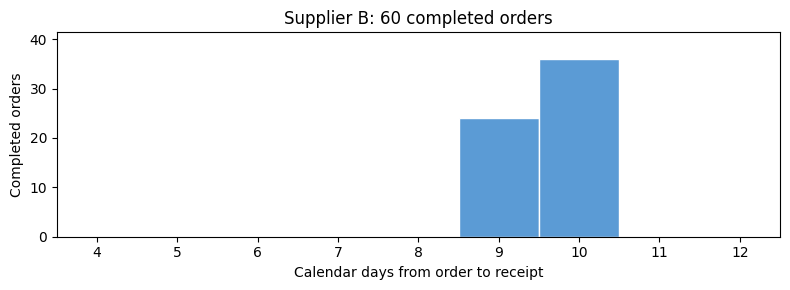

Use the mean for average speed and standard deviation for variation. Histograms share common axes; supplier sample sizes differ.


Completed POs                60.000000
Mean days                     9.600000
Std days                      0.494032
Promised-date OTD %         100.000000
In-full %                    96.666667
Flagged POs                  12.000000
Flagged PO %                 20.000000
Inspected units           35960.000000
Defective units             288.000000
Defective unit %              0.800890
Purchase EUR/unit             9.200000
Recorded cost EUR/unit       10.364071
Name: B, dtype: float64

In [8]:
# Write one or more function calls here.
# Select the function and its argshowuments from the reference above.
show_delivery(orders, supplier='B')

**Evidence and interpretation:**

_Record the relevant values with units and denominators. Answer each question and explain what your evidence supports._

## 2. Reporting: did supplier performance improve?

The team proposes changing its internal receipt target from **10 to 12 calendar days**, then reporting an improvement in supplier performance.

Choose the evidence needed to evaluate that proposed message. Make a controlled comparison using the same source records.

- Record both target percentages for each supplier and compare them with promised-date OTD.
- State precisely what changed and what did not.
- Write a more accurate sentence for the management report.

**Before running:** write which function(s) you selected and why.

**Function selection and reason:**

_Write your choice and reason here._

In [3]:
# Write one or more function calls here.
# Select the function and its arguments from the reference above.

**Evidence and interpretation:**

_Record the relevant values with units and denominators. Answer each question and explain what your evidence supports._

## 3. Quality: which comparison is justified?

Supplier B claims better quality than Supplier C because **a smaller percentage of its completed orders contains a defect**.

Choose the analyses needed to assess the claim from both an order and a piece perspective.

- Report affected orders / completed orders and defective pieces / inspected pieces for B and C.
- Does the supplier ranking change when the denominator changes?
- Which percentage is relevant to the stated acceptance criterion? Explain why the other measure can still matter.

**Before running:** write which function(s) you selected and why.

**Function selection and reason:**

_Write your choice and reason here._

In [4]:
# Write one or more function calls here.
# Select the function and its arguments from the reference above.

**Evidence and interpretation:**

_Record the relevant values with units and denominators. Answer each question and explain what your evidence supports._

## 4. Finance: is the lowest quote the lowest cost?

Finance favours Supplier A because its quoted purchase price is lowest.

Choose the analyses needed to assess this position. Compare all suppliers on a consistent EUR-per-received-piece basis.

- Identify the lowest purchase price and the lowest recorded procurement cost.
- Explain which included costs can change the ranking.
- State one important cost or business effect that this dataset cannot establish. Do not describe recorded cost as full lifecycle cost.

**Before running:** write which function(s) you selected and why.

**Function selection and reason:**

_Write your choice and reason here._

In [5]:
# Write one or more function calls here.
# Select the function and its arguments from the reference above.

**Evidence and interpretation:**

_Record the relevant values with units and denominators. Answer each question and explain what your evidence supports._

## 5. Supply planning: can the accepted suppliers cover July?

Apply the stated approval, delivery and quality requirements to the **10,000-unit July need**. Then assess the proposed reduction in the defective-piece ceiling from **1.0% to 0.5%**, holding every other rule and the supplier records unchanged.

Choose the function and settings needed to compare both decisions.

- Identify eligible suppliers, their combined capacity and any supply gap under each rule.
- Explain whether supplier quality changed in this comparison.
- Recommend the next action if the stricter rule leaves insufficient capacity. Do not assume additional capacity or approval without evidence.

**Before running:** write which function(s) you selected and why.

**Function selection and reason:**

_Write your choice and reason here._

In [6]:
# Write one or more function calls here.
# Select the function and its arguments from the reference above.

**Evidence and interpretation:**

_Record the relevant values with units and denominators. Answer each question and explain what your evidence supports._

## Purchasing recommendation

Prepare a short recommendation for the July requirement:

1. Recommend which supplier(s) remain acceptable under the current rule, distinguishing eligibility from lowest recorded cost.
2. Cite delivery, quality, cost and capacity evidence. Explain why a single “best supplier” ranking is insufficient.
3. Explain the consequence of the proposed stricter quality rule and the action needed before supply can be confirmed.

Submit the completed notebook with a compact supplier comparison table, at least two relevant charts, your five function-choice explanations and a recommendation of approximately 150 words. You may summarise values from your outputs in a Markdown table; no new calculation function is required.


**Complete your comparison table:**

| Measure | A | B | C |
|---|---:|---:|---:|
| Completed orders | — | — | — |
| Mean delivery time, days | — | — | — |
| Delivery standard deviation, days | — | — | — |
| Promised-date OTD, % | — | — | — |
| Affected orders, % | — | — | — |
| Defective inspected pieces, % | — | — | — |
| Purchase price, EUR/piece | — | — | — |
| Recorded cost, EUR/received piece | — | — | — |


**Your recommendation:**

_Write your recommendation here._